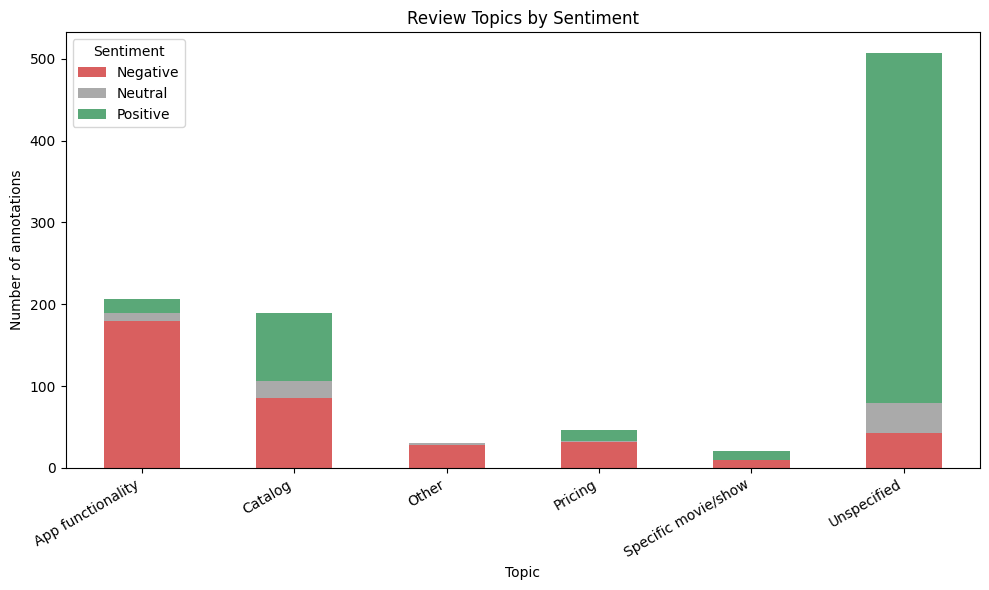

In [2]:

import pandas as pd
import matplotlib.pyplot as plt

# Load your annotated reviews
df = pd.read_csv("netflix_reviews_2022_sample_completed.csv")

topic_labels = {
    "c": "Catalog",
    "p": "Pricing",
    "a": "App functionality",
    "m": "Specific movie/show",
    "u": "Unspecified",
    "o": "Other"
}

sentiment_labels = {
    "+": "Positive",
    "-": "Negative",
    "0": "Neutral"
}

# Split reviews with multiple annotations
annotations = df.assign(
    annotation=df["annotation"].fillna("").str.split(",")
).explode("annotation")

annotations["annotation"] = annotations["annotation"].str.strip()

# Extract topic and sentiment
annotations["topic"] = annotations["annotation"].str[0].map(topic_labels)
annotations["sentiment"] = annotations["annotation"].str[1].map(sentiment_labels)

# Count annotations by topic and sentiment
counts = pd.crosstab(
    annotations["topic"],
    annotations["sentiment"]
).reindex(columns=["Negative", "Neutral", "Positive"], fill_value=0)

# Plot
ax = counts.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["#d95f5f", "#aaaaaa", "#5aa878"]
)

plt.title("Review Topics by Sentiment")
plt.xlabel("Topic")
plt.ylabel("Number of annotations")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()
